# Simultaneous sidebands for the Z2-Higgs Trotter step — and a QuTiP check that it works

### What we want: a larger interaction strength $J$
The controlled hop is what limits the simulation: today $J/2\pi \approx 19$ kHz. A Trotter step plays the LOC rotation, then the $W_{\rm sym}$ train on **links 0 and 2** together
(layer $L_{13}$), then on **link 1** alone (layer $L_2$): 16 sideband slots. We would like to fire

* all three **A legs at once**: Q1C1, Q2C2, Q3C3, then
* all three **B legs at once**: Q1C2, Q2C3, Q3C4,

so a step needs only 8 slots. Same physics per step, less time per step, so a **faster hop rate $J$ per µs**.

### What can go wrong
Inside a triplet the three pulses touch different transmons and different cavities, so playing them together
is the same as playing them one after another. The trouble is **between** the triplets: leg $A_{l+1}$
(q$_{l+1}$–C$_{l+1}$) and leg $B_l$ (q$_l$–C$_{l+1}$) both talk to cavity C$_{l+1}$. $W_{\rm sym}$ makes the hop out
of the commutator of the A and B pulses, and with all links on it also makes $[A_{l+1},B_l]$, which moves an
excitation **directly between two transmons** through that cavity. That term breaks Gauss' law, and it is
just as big as the hop.

### The fix
Every pulse in $W_{\rm sym}$ is played with a sign (a $\pi$ pump phase). Choosing the signs **per link** — links
0 and 2 with one pattern $P$, link 1 with another $Q$ — keeps every hop exactly as strong as before and makes
the transmon–transmon term cancel (**8-slot scheme**). That costs link 1 one order of Gauss protection, which a
**16-slot scheme** (link 1 plays $Q$ then $-Q$ within one step) gives back.

### This notebook
Builds the system **from scratch in QuTiP** (independent of the runtime code), then checks, step by step:

| | question | how |
|---|---|---|
| 1 | does the sign choice cancel the bad term on paper? | the second-order coefficients |
| 2 | is the bad term really in the naive step's generator, and gone with the fix? | $\log$ of the one-step unitary, projected on the operators |
| 3 | how fast does each scheme leave the Gauss sector? | one step on random in-sector states, versus pulse area |
| 4 | do the dynamics follow the exact Hamiltonian, and how much faster? | $\langle n\rangle$ of four preparations against µs |
| 5 | is Gauss' law kept over a whole run? | P(every $G_i$ as prepared) against $Jt$ |
| 6 | **the point: how large can $J$ be at today's quality?** | error and Gauss survival against $J/2\pi$, every scheme |
| 7 | does the runtime play exactly this circuit? | the runtime's theory against this QuTiP model |

Everything here is **lossless**: ideal pulses, no decoherence. The pulse areas, LOC angles and pulse lengths are
read from the current config.


## 0. The experiment's numbers

Each short sideband of area $\epsilon$ (a full swap is $\epsilon=\pi/2$), each LOC rotation $R_x(\theta)$, and
each pulse's length on the board. A step's duration:

* **layered** (today): $T = t_{\rm LOC} + 4\,(t_{B_{13}} + t_{A_{13}}) + 4\,(t_{B_2} + t_{A_2})$, where an $L_{13}$
  slot is as long as the longer of its two legs;
* **simultaneous** (8 slots): $T = t_{\rm LOC} + 4\,(t_B + t_A)$, a slot as long as the longest leg in it;
* **simultaneous_16** (16 slots, two $W_{\rm sym}$ per step, so twice the hop per step): $T = t_{\rm LOC} + 8\,(t_B + t_A)$.

$J = (\text{hop angle per step})/T$ with the same pulse areas, so the shorter the step per $W_{\rm sym}$, the larger $J$.


In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from scipy.linalg import logm
from acadia_qmsmt.utils import load_yaml

CONFIG = ("/home/tunmays_rsl_pc_wsl/boson/msmt_workbench/msmt_workbench/rfsoc/msmt/"
          "Tunmay_measurements/config_mced.yaml")                       # read only
cfg = load_yaml(CONFIG)
pulse = lambda section, name: cfg[f"{section}_stimulus"]["pulses"][name]
t_eff = lambda p: float(p["flat"]) + float(p["ramp"]) / 2                 # hann: flat + ramp/2
length = lambda p: np.ceil(round((float(p["ramp"]) + float(p["flat"])) / 5e-9, 6)) * 5e-9   # whole 5 ns cycles

# leg -> (config section, the pair's pulse prefix). Leg A of link l: q_l - C_l, leg B: q_l - C_{l+1}
LEGS = {"A0": ("rf1", "Q1C1"), "B0": ("rfb1", "Q1C2"), "A1": ("rf2", "Q2C2"),
        "B1": ("rfb2", "Q2C3"), "A2": ("rf3", "Q3C3"), "B2": ("rfb3", "Q3C4")}
EPS, LEN = {}, {}
for leg, (sec, pair) in LEGS.items():
    short, full = pulse(sec, f"{pair}_short"), pulse(sec, f"{pair}_swap")
    # area of the short pulse = (pi/2) x (its effective time / the full swap's) x (scale ratio)
    EPS[leg] = (np.pi / 2) * t_eff(short) / t_eff(full) * abs(short["scale"]) / abs(full["scale"])
    LEN[leg] = length(short)
THETA = [np.pi * abs(pulse(q, "R_x_short")["scale"]) / abs(pulse(q, "R_x_180")["scale"])
         * t_eff(pulse(q, "R_x_short")) / t_eff(pulse(q, "R_x_180")) for q in ("q1", "q2", "q3")]
T_LOC = length(pulse("q1", "R_x_short"))
STEP = {
    "layered": T_LOC + 4 * (max(LEN["B0"], LEN["B2"]) + max(LEN["A0"], LEN["A2"])) + 4 * (LEN["B1"] + LEN["A1"]),
    "simultaneous": T_LOC + 4 * (max(LEN[f"B{l}"] for l in range(3)) + max(LEN[f"A{l}"] for l in range(3))),
    "simultaneous_16": T_LOC + 8 * (max(LEN[f"B{l}"] for l in range(3)) + max(LEN[f"A{l}"] for l in range(3))),
}
WSYM_PER_STEP = {"layered": 1, "naive": 1, "simultaneous": 1, "simultaneous_16": 2}   # hop per step, in W_syms
JT = np.mean([2 * EPS[f"A{l}"] * EPS[f"B{l}"] for l in range(3)])         # hop angle per step

print("pulse areas eps:", {k: round(v, 3) for k, v in EPS.items()})
print("LOC angles theta:", np.round(THETA, 3), "rad")
print("short pulse lengths:", {k: f"{v*1e9:.0f} ns" for k, v in LEN.items()}, f"| LOC {T_LOC*1e9:.0f} ns")
for s, t in STEP.items():
    jt = JT * WSYM_PER_STEP[s]
    print(f"{s:16s} step T = {t*1e9:5.0f} ns   J T = {jt:.3f} rad/step   J/2pi = {jt / t / (2*np.pi) / 1e3:5.2f} kHz"
          f"   ({jt / t / (JT / STEP['layered']):.2f}x today's J)")


pulse areas eps: {'A0': 0.244, 'B0': 0.278, 'A1': 0.3, 'B1': 0.3, 'A2': 0.318, 'B2': 0.243}
LOC angles theta: [0.595 0.595 0.595] rad
short pulse lengths: {'A0': '110 ns', 'B0': '60 ns', 'A1': '60 ns', 'B1': '60 ns', 'A2': '60 ns', 'B2': '60 ns'} | LOC 150 ns
layered          step T =  1310 ns   J T = 0.157 rad/step   J/2pi = 19.03 kHz   (1.00x today's J)
simultaneous     step T =   830 ns   J T = 0.157 rad/step   J/2pi = 30.04 kHz   (1.58x today's J)
simultaneous_16  step T =  1510 ns   J T = 0.313 rad/step   J/2pi = 33.02 kHz   (1.74x today's J)


## The model in QuTiP

Three transmons q1, q2, q3 (levels $|g\rangle,|e\rangle$) and four cavities C1–C4, each kept to `DC` levels.
The pieces:

* **a sideband pulse** on leg (transmon $l$, cavity $c$) of area $\epsilon$ and pump phase $\varphi$:
  $\;U = \exp\!\big[-i\,\epsilon\,(e^{i\varphi} a_c\,\sigma^+_l + \text{h.c.})\big]$, $\sigma^+ = |e\rangle\langle g|$.
  A full swap $|e,0\rangle\to|g,1\rangle$ is $\epsilon=\pi/2$;
* **the LOC rotation**: $R_x(\theta) = \exp(-i\theta X_l/2)$ on every transmon;
* **$W_{\rm sym}$**: the 8 pulses B$-$, A$-$, B$+$, A$+$, B$+$, A$+$, B$-$, A$-$ (a $-$ is a $\pi$ pump phase).
  Its net effect is the hop $\exp(-2\epsilon_A\epsilon_B[K_A,K_B])$ with $K = a\sigma^+ + \text{h.c.}$;
* **Gauss' law**: $G_i = X_{i-1}\,(-1)^{n_i}\,X_i$ (an end site has only one $X$). The exact Hamiltonian
  conserves every $G_i$.

The **exact** evolution is $e^{-inH}$ with the target step Hamiltonian
$$H = \sum_l \tfrac{\theta_l}{2}X_l \;-\; 2i\sum_l \epsilon_{A,l}\epsilon_{B,l}\,[K_{A,l},K_{B,l}],$$
the same for every scheme.


In [2]:
DC = 6                                   # cavity levels kept: enough for 2 photons (checked in section 7)
NQ, NCAV = 3, 4


class Chain:
    """Transmons 0..nq-1 then cavities 0..nq, all operators on the full space."""
    def __init__(self, nq=NQ, dc=DC):
        self.nq, self.nc, self.dc = nq, nq + 1, dc
        self.dims = [2] * nq + [dc] * (nq + 1)
        g, e = qt.basis(2, 0), qt.basis(2, 1)
        self.sp_local = e * g.dag()                                  # sigma+ = |e><g|
        self.a_local = qt.destroy(dc)

    def on(self, op, *targets):
        return qt.expand_operator(op, dims=self.dims, targets=list(targets))

    def q(self, l):        return l                                  # index of transmon l
    def c(self, k):        return self.nq + k                        # index of cavity k
    def X(self, l):        return self.on(qt.sigmax(), self.q(l))
    def n(self, k):        return self.on(qt.num(self.dc), self.c(k))
    def parity(self, k):   return self.on((1j * np.pi * qt.num(self.dc)).expm(), self.c(k))
    def K(self, l, k):     # a_k sigma+_l + h.c. on (transmon l, cavity k)
        op = self.on(qt.tensor(self.sp_local, self.a_local), self.q(l), self.c(k))
        return op + op.dag()

    def sideband(self, l, k, eps, phase):
        local = qt.tensor(self.sp_local, self.a_local) * np.exp(1j * phase)
        U = (-1j * eps * (local + local.dag())).expm()
        return self.on(U, self.q(l), self.c(k))

    def loc(self, thetas):
        U = None
        for l, th in enumerate(thetas):
            u = self.on((-1j * th / 2 * qt.sigmax()).expm(), self.q(l))
            U = u if U is None else u * U
        return U

    def G(self, i):
        out = self.parity(i)
        if i - 1 >= 0:
            out = self.X(i - 1) * out
        if i <= self.nq - 1:
            out = out * self.X(i)
        return out

    def state(self, photons, x_signs):
        """|n_1 .. n_C> with transmon l in the X eigenstate of sign x_signs[l]."""
        g, e = qt.basis(2, 0), qt.basis(2, 1)
        qs = [(g + s * e).unit() for s in x_signs]
        cs = [qt.basis(self.dc, n) for n in photons]
        return qt.tensor(*qs, *cs)


# W_sym in time order: (leg kind, sign); a - sign is a pi pump phase
WSYM = [("B", -1), ("A", -1), ("B", +1), ("A", +1), ("B", +1), ("A", +1), ("B", -1), ("A", -1)]
P = (+1, -1, -1, +1)                 # W_sym's own sign pattern (flipped): third-order protected
Q = (-1, +1, -1, +1)                 # the other pattern with the same hop
# per scheme: the sign of (links 0, 2) and (link 1) in each A slot (= each B slot); slots alternate B, A, ...
SIGNS = {"naive":           ((-1, +1, +1, -1), (-1, +1, +1, -1)),     # W_sym's own signs on every link
         "simultaneous":    (P, Q),
         "simultaneous_16": (P + P, Q + tuple(-x for x in Q))}


def cavity_of(kind, l):
    return l if kind == "A" else l + 1


def schedule(scheme, nq=NQ):
    """One step's sideband pulses, in play order: a list of SLOTS, each a list of (link, cavity, sign).
    Pulses in one slot touch disjoint modes, so their order inside the slot does not matter."""
    if scheme == "layered":                       # today's circuit: links 0 and 2, then link 1
        layers = [(0, 2), (1,)] if nq == 3 else [(0,), (1,)]
        return [[(l, cavity_of(kind, l), sign) for l in layer] for layer in layers for kind, sign in WSYM]
    signs = SIGNS[scheme]                         # all links in every slot, signs per link
    out = []
    for k in range(2 * len(signs[0])):
        kind = "B" if k % 2 == 0 else "A"
        out.append([(l, cavity_of(kind, l), signs[l % 2][k // 2]) for l in range(nq)])
    return out


def step_ops(ch, scheme, eps, thetas):
    """The step as a list of unitaries in play order: the LOC, then every pulse."""
    ops = [ch.loc(thetas)]
    for slot in schedule(scheme, ch.nq):
        for l, k, sign in slot:
            kind = "A" if k == l else "B"
            ops.append(ch.sideband(l, k, eps[f"{kind}{l}"], 0.0 if sign > 0 else np.pi))
    return ops


def target_H(ch, eps, thetas):
    """The step Hamiltonian every scheme is meant to apply (exact evolution = exp(-i n H))."""
    H = sum(th / 2 * ch.X(l) for l, th in enumerate(thetas))
    for l in range(ch.nq):
        KA, KB = ch.K(l, l), ch.K(l, l + 1)
        H += -2j * eps[f"A{l}"] * eps[f"B{l}"] * (KA * KB - KB * KA)
    return H


CH = Chain()
print("Hilbert space dims", CH.dims, "=", int(np.prod(CH.dims)), "states")


Hilbert space dims [2, 2, 2, 6, 6, 6, 6] = 10368 states


## 1. On paper: the second-order coefficients

For two legs whose four pulses carry signs $a$ (A leg) and $b$ (B leg), $W_{\rm sym}$'s second-order term is
$D(a,b)\,[K_A,K_B]$ with
$$D(a,b)=a^{\mathsf T}M\,b,\qquad M_{ij}=+1 \text{ if A pulse } i \text{ comes before B pulse } j,\ -1 \text{ otherwise}.$$
The **hop** of link $l$ is $D(a_l,b_l)$ — we want $-4$, $W_{\rm sym}$'s value. The **bad term** through cavity
C$_{l+1}$ is $D(a_{l+1},b_l)$ — we want $0$.


In [3]:
def D(a, b):
    """a^T M b: A pulse i sits in slot 2i+1, B pulse j in slot 2j."""
    n = len(a)
    M = np.array([[1 if 2 * i + 1 < 2 * j else -1 for j in range(n)] for i in range(n)])
    return int(np.asarray(a) @ M @ np.asarray(b))

def signs(scheme, kind, l):
    return [sg for slot in schedule(scheme) for (ll, k, sg) in slot
            if ll == l and (k == l) == (kind == "A")]

print(f"{'scheme':16s} {'hop link0':>9s} {'hop link1':>9s} {'hop link2':>9s} {'bad via C2':>11s} {'bad via C3':>11s}")
for scheme in ("naive", "simultaneous", "simultaneous_16"):
    a = [signs(scheme, "A", l) for l in range(3)]
    b = [signs(scheme, "B", l) for l in range(3)]
    print(f"{scheme:16s} {D(a[0], b[0]):9d} {D(a[1], b[1]):9d} {D(a[2], b[2]):9d} "
          f"{D(a[1], b[0]):11d} {D(a[2], b[1]):11d}")
print("layered: the bad pairs are never in the same layer, so the term cannot arise")


scheme           hop link0 hop link1 hop link2  bad via C2  bad via C3
naive                   -4        -4        -4          -4          -4
simultaneous            -4        -4        -4           0           0
simultaneous_16         -8        -8        -8           0           0
layered: the bad pairs are never in the same layer, so the term cannot arise


## 2. Is the bad term really in the step? The generator of one step

Take **two links** (q1, q2 and C1, C2, C3 — the smallest chain with a shared cavity), build the one-step
unitary $U$ of each scheme with small pulses ($\epsilon$ scaled down, LOC off), and take its generator
$H_{\rm eff} = i\log U$. Project it onto

* the **hop** operator of link 0, $-i[K_{A0},K_{B0}]$ — should be the same for every scheme;
* the **bad** operator, $-i[K_{A1},K_{B0}]$ (q1 ↔ q2 through C2) — should be zero.

(Restricted to states with at most one excitation, where the truncation plays no role.)


In [4]:

two = Chain(nq=2, dc=3)

def generator(scheme, scale):
    eps = {k: v * scale for k, v in EPS.items()}
    U = qt.qeye(two.dims)
    for op in step_ops(two, scheme, eps, [0.0, 0.0])[1:]:          # LOC off: pulses only
        U = op * U
    H = 1j * logm(U.full())
    # keep states with at most one excitation (photons + excited transmons): truncation cannot matter there
    exc = (sum(two.n(k) for k in range(two.nc))                                  # photons
           + sum(two.on(qt.num(2), two.q(l)) for l in range(two.nq)))           # excited transmons
    keep = np.real(np.diag(exc.full())) <= 1
    P = np.diag(keep.astype(float))
    return P @ H @ P, P

def coefficient(H, op, P):
    o = P @ op.full() @ P
    return np.real(np.vdot(o, H) / np.vdot(o, o))

hop0 = -1j * (two.K(0, 0) * two.K(0, 1) - two.K(0, 1) * two.K(0, 0))     # the hop of link 0
bad = -1j * (two.K(1, 1) * two.K(0, 1) - two.K(0, 1) * two.K(1, 1))      # q1 <-> q2 through C2
print(f"{'scheme':16s} {'scale':>5s} {'hop coefficient':>16s} {'bad coefficient':>16s}   (W_sym's hop: 2 eps_A0 eps_B0 s^2 per W_sym)")
for scale in (0.25, 0.5):
    for scheme in ("layered", "naive", "simultaneous", "simultaneous_16"):
        H, P = generator(scheme, scale)
        print(f"{scheme:16s} {scale:5.2f} {coefficient(H, hop0, P):16.5f} {coefficient(H, bad, P):16.5f}"
              f"   {2 * EPS['A0'] * EPS['B0'] * scale**2 * WSYM_PER_STEP[scheme]:.5f}")


scheme           scale  hop coefficient  bad coefficient   (W_sym's hop: 2 eps_A0 eps_B0 s^2 per W_sym)
layered           0.25          0.00848          0.00000   0.00849


naive             0.25          0.00845          0.01036   0.00849
simultaneous      0.25          0.00845         -0.00000   0.00849


simultaneous_16   0.25          0.01691          0.00000   0.01698
layered           0.50          0.03376          0.00000   0.03396


naive             0.50          0.03340          0.04066   0.03396


simultaneous      0.50          0.03340         -0.00000   0.03396


simultaneous_16   0.50          0.06679          0.00000   0.06793


## 3. How fast does each scheme leave the Gauss sector?

Start in a **random state inside** a Gauss sector (one photon; the sector of $|0,0,0,1\rangle$ with transmons
$(-,-,+)$), play **one** step (LOC included), and measure the probability of having left the sector. Then
shrink every pulse area by a factor $s$. The power of $s$ is the order at which Gauss' law breaks: $s^4$ = the
second-order exchange is there, $s^6$ = a third-order term is left, $s^8$ = protected to third order like
today's circuit. The vertical line is this config ($s=1$).


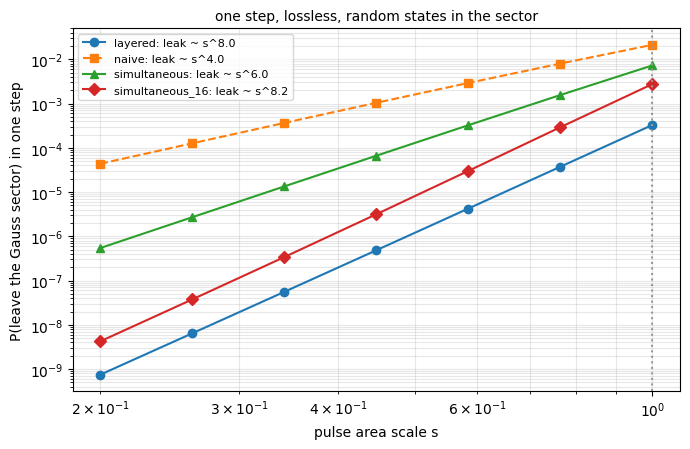

In [5]:

def number_projector(ch, N):
    tot = np.real((sum(ch.n(k) for k in range(ch.nc))).diag())
    return qt.qdiags((tot == N).astype(float), 0, dims=[ch.dims, ch.dims])

def sector_projector(ch, photons, x_signs):
    """Onto the prep's photon number AND every G_i equal to the prep's."""
    ref = ch.state(photons, x_signs)
    P = number_projector(ch, sum(photons))
    for i in range(ch.nc):
        g0 = np.sign(qt.expect(ch.G(i), ref))
        P = 0.5 * (qt.qeye(ch.dims) + g0 * ch.G(i)) * P
    return P

PROJ = sector_projector(CH, (0, 0, 0, 1), (-1, -1, 1))
CH_dim = int(np.prod(CH.dims))

def leak_one_step(scheme, scale, trials=6, seed=0):
    rng = np.random.default_rng(seed)
    eps = {k: v * scale for k, v in EPS.items()}
    theta = [t * WSYM_PER_STEP[scheme] for t in THETA]          # same g/J for every scheme
    ops = step_ops(CH, scheme, eps, theta)
    out = []
    for _ in range(trials):
        psi = qt.Qobj(rng.normal(size=CH_dim) + 1j * rng.normal(size=CH_dim), dims=[CH.dims, [1] * len(CH.dims)])
        psi = (PROJ * psi).unit()
        for op in ops:
            psi = op * psi
        out.append(1 - (PROJ * psi).norm() ** 2)
    return np.mean(out)

scales = np.geomspace(0.2, 1.0, 7)
fig, ax = plt.subplots(figsize=(7, 4.6))
for scheme, style in (("layered", "o-"), ("naive", "s--"), ("simultaneous", "^-"), ("simultaneous_16", "D-")):
    leak = np.array([leak_one_step(scheme, s) for s in scales])
    order = np.polyfit(np.log(scales[:3]), np.log(leak[:3]), 1)[0]
    ax.loglog(scales, leak, style, label=f"{scheme}: leak ~ s^{order:.1f}")
ax.axvline(1, color="0.6", ls=":")
ax.set_xlabel("pulse area scale s"); ax.set_ylabel("P(leave the Gauss sector) in one step")
ax.set_title("one step, lossless, random states in the sector", fontsize=10)
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 4. Do the dynamics follow the exact Hamiltonian? (today's pulse areas)

Four preparations to the same $Jt$ as 40 of today's steps. Plotted against **physical time**:
$\langle n\rangle$ of the site that starts occupied, post-selected on the photon number (what the experiment
reports), for the **exact** evolution (black dashed) and each scheme's circuit. Every scheme keeps today's
$g/J$ (its LOC angle scales with its hop per step).

* **confined** — $|0,0,0,1\rangle$, transmons $(-,-,-)$: the photon is held by its string;
* **tunnelling** — $|0,0,0,1\rangle$, $(-,-,+)$: the photon moves;
* **meson** — $|1,1,0,0\rangle$, the Gauss state;
* **two-photon Gauss** — $|0,1,1,0\rangle$.

The simultaneous circuits get to the same $Jt$ in fewer µs — that is the larger $J$.


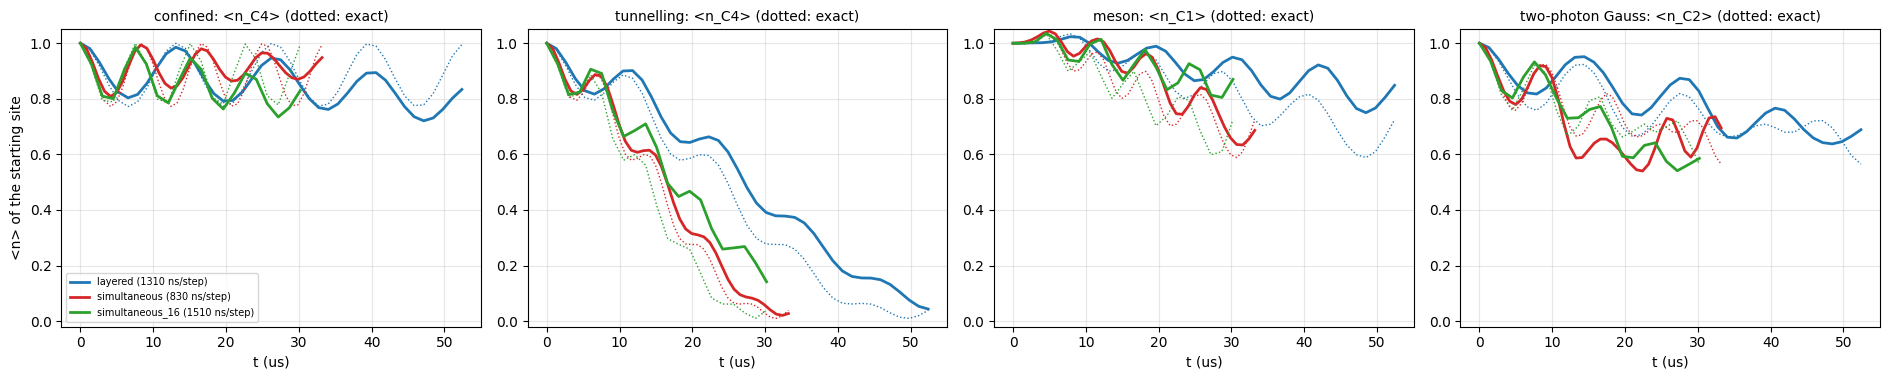

prep                               layered     simultaneous  simultaneous_16
confined           max|d<n>|         0.161            0.100            0.165    
tunnelling         max|d<n>|         0.218            0.383            0.387    
meson              max|d<n>|         0.181            0.239            0.219    
two-photon Gauss   max|d<n>|         0.243            0.293            0.248    


In [6]:

from scipy.sparse.linalg import expm_multiply

PREPS = {"confined": ((0, 0, 0, 1), (-1, -1, -1)),
         "tunnelling": ((0, 0, 0, 1), (-1, -1, 1)),
         "meson": ((1, 1, 0, 0), (-1, 1, 1)),
         "two-photon Gauss": ((0, 1, 1, 0), (1, -1, 1))}
JT_TARGET = 40 * JT                       # how far 40 of today's steps get
n_ops = [CH.n(k) for k in range(CH.nc)]

def run(photons, x_signs, scheme, scale=1.0):
    """Per step: post-selected <n_i>, P(every G_i as prepared), and the time axis (us) -- up to JT_TARGET."""
    eps = {k: v * scale for k, v in EPS.items()}
    w = 1 if scheme == "exact" else WSYM_PER_STEP[scheme]
    theta = [t * w * scale**2 for t in THETA]                        # same g/J as today
    nsteps = int(round(JT_TARGET / (JT * w * scale**2)))
    keep = number_projector(CH, sum(photons))
    proj = sector_projector(CH, photons, x_signs)
    psi = CH.state(photons, x_signs)
    if scheme == "exact":
        H = target_H(CH, eps, theta).to("CSR").data.as_scipy()
    else:
        ops = step_ops(CH, scheme, eps, theta)
    n_out, gauss = [], []
    for step in range(nsteps + 1):
        if step:
            if scheme == "exact":
                psi = qt.Qobj(expm_multiply(-1j * H, psi.full().ravel()), dims=psi.dims)
            else:
                for op in ops:
                    psi = op * psi
        kept = keep * psi
        w8 = kept.norm() ** 2
        n_out.append([qt.expect(n, kept) / w8 for n in n_ops])
        gauss.append((proj * psi).norm() ** 2 / w8)
    t_us = np.arange(nsteps + 1) * (STEP[scheme] if scheme in STEP else 0) * 1e6
    jt = np.arange(nsteps + 1) * JT * w * scale**2
    return {"n": np.array(n_out), "gauss": np.array(gauss), "t_us": t_us, "Jt": jt}

SCHEMES_SHOWN = {"layered": "C0", "simultaneous": "C3", "simultaneous_16": "C2"}
RES = {name: {sch: run(*prep, sch) for sch in ("exact", *SCHEMES_SHOWN)} for name, prep in PREPS.items()}

fig, axs = plt.subplots(1, 4, figsize=(19, 3.9))
for ax, (name, (photons, _)) in zip(axs, PREPS.items()):
    start = int(np.argmax(photons))
    ex = RES[name]["exact"]
    for sch, col in SCHEMES_SHOWN.items():
        r = RES[name][sch]
        ax.plot(r["t_us"], r["n"][:, start], "-", color=col, lw=2,
                label=f"{sch} ({STEP[sch]*1e9:.0f} ns/step)")
        # the exact evolution on this scheme's clock: same J t at the same step
        ax.plot(r["t_us"], np.interp(r["Jt"], ex["Jt"], ex["n"][:, start]), ":", color=col, lw=1)
    ax.set_title(f"{name}: <n_C{start + 1}> (dotted: exact)", fontsize=10); ax.set_xlabel("t (us)")
    ax.set_ylim(-0.02, 1.05); ax.grid(alpha=0.3)
axs[0].set_ylabel("<n> of the starting site"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'prep':18s} {'':6s}" + "".join(f"{sch:>17s}" for sch in SCHEMES_SHOWN))
for name in PREPS:
    ex = RES[name]["exact"]
    errs = [np.abs(RES[name][sch]["n"] - np.array([np.interp(RES[name][sch]["Jt"], ex["Jt"], ex["n"][:, i])
                                                   for i in range(CH.nc)]).T).max() for sch in SCHEMES_SHOWN]
    print(f"{name:18s} {'max|d<n>|':10s}" + "".join(f"{e:13.3f}    " for e in errs))


## 5. Gauss' law over a whole run

The probability that **every** $G_i$ is still what was prepared (exact: 1 at all times), against $Jt$.


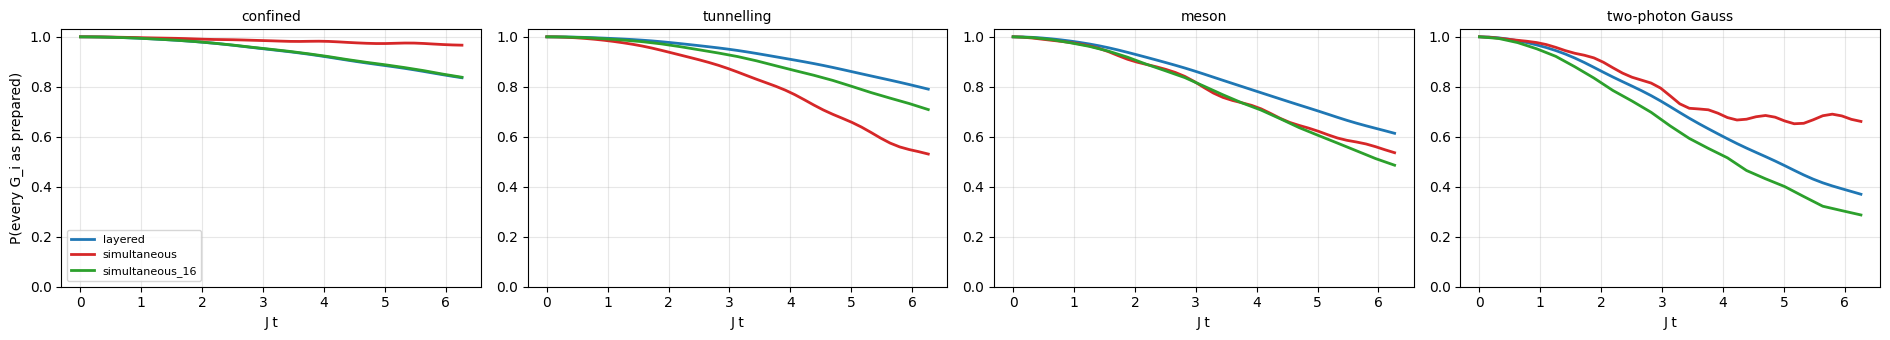

In [7]:

fig, axs = plt.subplots(1, 4, figsize=(19, 3.5))
for ax, name in zip(axs, PREPS):
    for sch, col in SCHEMES_SHOWN.items():
        r = RES[name][sch]
        ax.plot(r["Jt"], r["gauss"], "-", color=col, lw=2, label=sch)
    ax.set_title(name, fontsize=10); ax.set_xlabel("J t"); ax.set_ylim(0, 1.03); ax.grid(alpha=0.3)
axs[0].set_ylabel("P(every G_i as prepared)"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()


## 6. The point: how large can $J$ be at today's quality?

A larger $J$ is bought with larger pulse areas, which cost Trotter error and Gauss-law leakage. So the fair
question is: **at the quality the experiment has today, how large a $J$ does each scheme reach?** Every
scheme is run to the same $Jt$ (40 of today's steps) at several pulse-area scales $s$, keeping today's $g/J$.
On the x-axis: $J/2\pi$ (= hop per step / step time). On the y-axis: the worst $|\langle n\rangle - $exact$|$ and the worst
Gauss survival over the four preparations. Today's operating point is the blue dot at $s=1$; a scheme whose
curve passes the same height further right gives a larger $J$ at the same quality.


layered          s = 0.80   J/2pi =  12.2 kHz   worst max|d<n>| = 0.158   worst Gauss survival = 0.676


layered          s = 0.90   J/2pi =  15.4 kHz   worst max|d<n>| = 0.201   worst Gauss survival = 0.529


layered          s = 1.00   J/2pi =  19.0 kHz   worst max|d<n>| = 0.243   worst Gauss survival = 0.370


layered          s = 1.10   J/2pi =  23.0 kHz   worst max|d<n>| = 0.272   worst Gauss survival = 0.233


simultaneous     s = 0.70   J/2pi =  14.7 kHz   worst max|d<n>| = 0.159   worst Gauss survival = 0.821


...

simultaneous     s = 1.00   J/2pi =  30.0 kHz   worst max|d<n>| = 0.383   worst Gauss survival = 0.531
simultaneous     s = 1.10   J/2pi =  36.3 kHz   worst max|d<n>| = 0.437   worst Gauss survival = 0.401


simultaneous_16  s = 0.70   J/2pi =  16.2 kHz   worst max|d<n>| = 0.138   worst Gauss survival = 0.755


simultaneous_16  s = 0.80   J/2pi =  21.1 kHz   worst max|d<n>| = 0.210   worst Gauss survival = 0.615


simultaneous_16  s = 0.90   J/2pi =  26.7 kHz   worst max|d<n>| = 0.292   worst Gauss survival = 0.429


simultaneous_16  s = 1.00   J/2pi =  33.0 kHz   worst max|d<n>| = 0.387   worst Gauss survival = 0.287


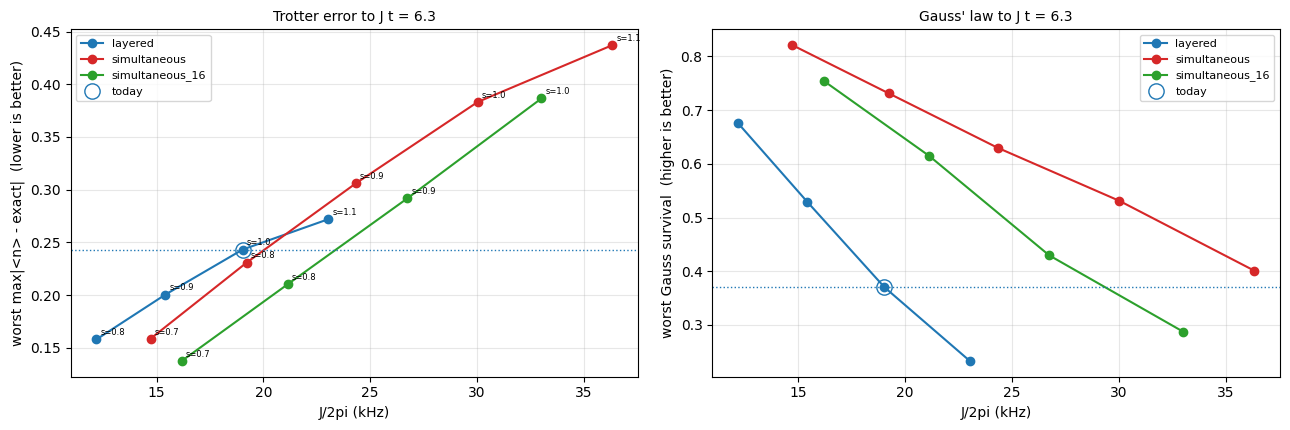

today (layered, s = 1): J/2pi = 19.0 kHz, worst error 0.243, worst Gauss survival 0.370
scheme            J at today error  J at today Gauss
layered               19.0 kHz (1.00x)      19.0 kHz (1.00x)
simultaneous          20.1 kHz (1.05x)      36.3 kHz (1.91x)
simultaneous_16       23.4 kHz (1.23x)      29.4 kHz (1.54x)


In [8]:

SCAN = {"layered": (0.8, 0.9, 1.0, 1.1), "simultaneous": (0.7, 0.8, 0.9, 1.0, 1.1),
        "simultaneous_16": (0.7, 0.8, 0.9, 1.0)}
rows = []
for sch, scales in SCAN.items():
    for sc in scales:
        err, gmin = 0.0, 1.0
        for name, (photons, x) in PREPS.items():
            r = run(photons, x, sch, sc)
            exact = RES[name]["exact"]
            ref = np.array([np.interp(r["Jt"], exact["Jt"], exact["n"][:, i]) for i in range(CH.nc)]).T
            err = max(err, np.abs(r["n"] - ref).max())
            gmin = min(gmin, r["gauss"].min())
        J = JT * WSYM_PER_STEP[sch] * sc**2 / STEP[sch] / (2 * np.pi) / 1e3
        rows.append((sch, sc, J, err, gmin))
        print(f"{sch:16s} s = {sc:.2f}   J/2pi = {J:5.1f} kHz   worst max|d<n>| = {err:.3f}   worst Gauss survival = {gmin:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for sch, col in SCHEMES_SHOWN.items():
    r = [row for row in rows if row[0] == sch]
    J = [x[2] for x in r]
    axs[0].plot(J, [x[3] for x in r], "o-", color=col, label=sch)
    axs[1].plot(J, [x[4] for x in r], "o-", color=col, label=sch)
    for x in r:
        axs[0].annotate(f"s={x[1]:.1f}", (x[2], x[3]), fontsize=6, xytext=(3, 3), textcoords="offset points")
today = [row for row in rows if row[0] == "layered" and row[1] == 1.0][0]
for ax, k, lab in ((axs[0], 3, "worst max|<n> - exact|  (lower is better)"),
                   (axs[1], 4, "worst Gauss survival  (higher is better)")):
    ax.axhline(today[k], color="C0", ls=":", lw=1)
    ax.plot(today[2], today[k], "o", color="C0", ms=11, mfc="none", label="today")
    ax.set_xlabel("J/2pi (kHz)"); ax.set_ylabel(lab); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axs[0].set_title(f"Trotter error to J t = {JT_TARGET:.1f}", fontsize=10)
axs[1].set_title(f"Gauss' law to J t = {JT_TARGET:.1f}", fontsize=10)
plt.tight_layout(); plt.show()

# The answer, read off the curves: the J each scheme reaches at TODAY's quality (linear interpolation)
print(f"today (layered, s = 1): J/2pi = {today[2]:.1f} kHz, worst error {today[3]:.3f}, worst Gauss survival {today[4]:.3f}")
print(f"{'scheme':16s} {'J at today error':>17s} {'J at today Gauss':>17s}")
for sch in SCHEMES_SHOWN:
    r = sorted([row for row in rows if row[0] == sch], key=lambda x: x[2])
    J = np.array([x[2] for x in r])
    J_err = np.interp(today[3], [x[3] for x in r], J)                     # error rises with J
    J_g = np.interp(-today[4], [-x[4] for x in r], J)                       # survival falls with J
    print(f"{sch:16s} {J_err:9.1f} kHz ({J_err / today[2]:.2f}x) {J_g:9.1f} kHz ({J_g / today[2]:.2f}x)")


## 7. Does the runtime play exactly this circuit?

`z2_higgs_simulation.pulse_list(..., scheme=...)` is the schedule the runtime plays and its theory overlays. Its
lossless circuit is compared here with this QuTiP model, slot by slot and step by step (the small remaining
difference is the cavity truncation: `DC` levels here, a shared photon budget there).


In [9]:

from msmt_workbench.rfsoc.runtimes.quantum_simulation import z2_higgs_simulation as Z

for scheme in ("layered", "simultaneous", "simultaneous_16"):
    rt = [sorted((l, k, +1 if abs(ph) < 1e-9 else -1) for l, k, ph, _a in legs)
          for _layer, legs in Z.pulse_list(3, EPS, 0.0, scheme)]
    print(f"{scheme:16s} schedule identical to the runtime's: {rt == [sorted(slot) for slot in schedule(scheme)]}")

for name, (photons, x) in PREPS.items():
    worst = 0.0
    for scheme in SCHEMES_SHOWN:
        r = RES[name][scheme]
        w = WSYM_PER_STEP[scheme]
        z = Z.theory_curves(list(photons), EPS, [t * w for t in THETA], list(range(len(r["Jt"]))),
                            transmons=x, scheme=scheme)
        worst = max(worst, np.abs(np.asarray(z["circuit"]["ps_mean_n"]) - r["n"]).max())
    print(f"{name:18s} runtime theory vs this QuTiP model, every scheme: max |d<n_i>| = {worst:.1e}")


layered          schedule identical to the runtime's: True
simultaneous     schedule identical to the runtime's: True
simultaneous_16  schedule identical to the runtime's: True


confined           runtime theory vs this QuTiP model, every scheme: max |d<n_i>| = 1.5e-04


tunnelling         runtime theory vs this QuTiP model, every scheme: max |d<n_i>| = 9.1e-04


meson              runtime theory vs this QuTiP model, every scheme: max |d<n_i>| = 2.4e-03


two-photon Gauss   runtime theory vs this QuTiP model, every scheme: max |d<n_i>| = 7.5e-03


## Verdict

* **Naive simultaneous** (every link with $W_{\rm sym}$'s own signs): the transmon–transmon term is in the step's
  generator as large as the hop (section 2) and Gauss' law breaks at second order (section 3). **Do not use.**
* **simultaneous** (8 slots, signs $P,Q,P$): the bad term is cancelled (sections 1, 2); Gauss' law breaks only at
  third order (section 3). Same hop per step in a shorter step: the largest $J$ per µs at a given pulse area.
* **simultaneous_16** (16 slots, $P\,P$ on links 0 and 2, $Q,-Q$ on link 1): also cancels the third-order leak, so
  Gauss' law is protected to the same order as today's circuit (section 3). Its $J$ is **not** halved -- each step
  carries two $W_{\rm sym}$ of hop and pays the LOC once, so $J$ is slightly *higher* than the 8-slot scheme's at the
  same pulse areas (section 0). Its cost is a **coarser Trotter step**: twice the hop per step and, at the same
  $g/J$, twice the LOC angle per step, so a larger LOC/hop splitting error per step. At today's pulse areas that
  outweighs its better order (section 6: worse Gauss survival than the 8-slot scheme at $s=1$); it pays off only at
  smaller pulse areas. It also samples the dynamics half as often.
* **Default: the 8-slot `simultaneous` scheme** at today's pulse areas.
* **Section 6 answers the question** (its last printout): the $J$ each scheme reaches at today's quality.
  At today's Gauss-law survival both simultaneous schemes reach a much larger $J$; at today's $\langle n\rangle$
  accuracy the gain is smaller, largest for `simultaneous_16`. The limiting $\langle n\rangle$ error is the
  Trotter splitting of the LOC and the hop, common to every scheme.
* The runtime's schedules are exactly these circuits (section 7).
